# Group Members: Jonah Blackmon, Emily Lucas, Kevin Le
# Eids: jkb3578, egl827, kl37995

# Intro: 
For our models we used two datasets on Austin animal cen-
ter intakes and outcomes. These datasets contain information
about animals in Austin’s animal center system and contain
features detailing the AnimalID (so we can index animals
across datasets), age, species, and outcome which is our target
column among others. We find that animals in Austin centers
may have unclear outcomes for their future, we hope to
provide clarity and shed some light on this matter to help
better understand what factors play into the current outcomes
of these innocent creatures and potentially give centers new
direction to focus on to help increase the likelihood that every
animal finds their forever home. For these datasets our goal
is to train a model that can take an animal’s information and
predict the outcome of the animal categorically.

In [121]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np
import re

%matplotlib inline

pd.__version__

 

'2.1.4'

# Preprocessing: 

## Load and Merge

In [122]:
outcome_df = pd.read_csv(filepath_or_buffer="./adoption_data_outcome.csv").drop_duplicates()
intake_df = pd.read_csv(filepath_or_buffer="./adoption_data_intake.csv").drop_duplicates()

intake_df["DateTime"] = pd.to_datetime(intake_df["DateTime"], format="%m/%d/%Y %I:%M:%S %p")
outcome_df["DateTime"] = pd.to_datetime(outcome_df["DateTime"].str[:19])  # some rows carry a timezone suffix

# pair same animal visits
intake_df = intake_df.sort_values(["Animal ID", "DateTime"])
outcome_df = outcome_df.sort_values(["Animal ID", "DateTime"])
intake_df["Visit"] = intake_df.groupby("Animal ID").cumcount()
outcome_df["Visit"] = outcome_df.groupby("Animal ID").cumcount()

df = pd.merge(intake_df, outcome_df[["Animal ID", "Visit", "DateTime", "Outcome Type"]],
              on=["Animal ID", "Visit"], how="inner", suffixes=("", " Outcome"))

# drop pairs where the outcome is before the intake (stay started before the dataset did)
stay_days = (df["DateTime Outcome"] - df["DateTime"]).dt.total_seconds() / 86400
df = df[stay_days >= -1].copy()

print(df.shape)
display(df.head())


(172673, 15)


,Animal ID,Name,DateTime,MonthYear,Found Location,Intake Type,Intake Condition,Animal Type,Sex upon Intake,Age upon Intake,Breed,Color,Visit,DateTime Outcome,Outcome Type
0,A006100,Scamp,2014-03-07 14:26:00,March 2014,8700 Research in Austin (TX),Public Assist,Normal,Dog,Neutered Male,6 years,Spinone Italiano Mix,Yellow/White,0,2014-03-08 17:10:00,Return to Owner
1,A006100,Scamp,2014-12-19 10:21:00,December 2014,8700 Research Blvd in Austin (TX),Public Assist,Normal,Dog,Neutered Male,7 years,Spinone Italiano Mix,Yellow/White,1,2014-12-20 16:35:00,Return to Owner
2,A006100,Scamp,2017-12-07 14:07:00,December 2017,Colony Creek And Hunters Trace in Austin (TX),Stray,Normal,Dog,Neutered Male,10 years,Spinone Italiano Mix,Yellow/White,2,2017-12-07 00:00:00,Return to Owner
3,A047759,Oreo,2014-04-02 15:55:00,April 2014,Austin (TX),Owner Surrender,Normal,Dog,Neutered Male,10 years,Dachshund,Tricolor,0,2014-04-07 15:12:00,Transfer
4,A134067,Bandit,2013-11-16 09:02:00,November 2013,12034 Research Blvd in Austin (TX),Public Assist,Injured,Dog,Neutered Male,16 years,Shetland Sheepdog,Brown/White,0,2013-11-16 11:54:00,Return to Owner


# Exploration before clean:

Missing values per column:
Animal ID               0
Name                49706
DateTime                0
MonthYear               0
Found Location          0
Intake Type             0
Intake Condition        0
Animal Type             0
Sex upon Intake         1
Age upon Intake         0
Breed                   0
Color                   0
Visit                   0
DateTime Outcome        0
Outcome Type           46
dtype: int64

Outcome Type:
Outcome Type
Adoption           83883
Transfer           48448
Return to Owner    25605
Euthanasia         10790
Died                1662
Rto-Adopt           1238
Disposal             875
Missing               91
NaN                   46
Relocate              28
Stolen                 5
Lost                   2
Name: count, dtype: int64

Animal Type:
Animal Type
Dog          93942
Cat          68873
Other         8948
Bird           877
Livestock       33
Name: count, dtype: int64

Unique values -> Breed: 3000  Color: 660  Intake Condition: 20

Odd 

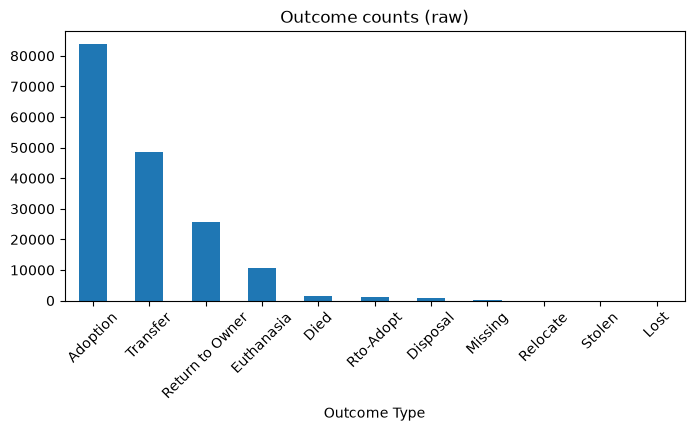

In [123]:
print("Missing values per column:")
print(df.isna().sum())
print("\nOutcome Type:")
print(df["Outcome Type"].value_counts(dropna=False))
print("\nAnimal Type:")
print(df["Animal Type"].value_counts())
print("\nUnique values -> Breed:", df["Breed"].nunique(), " Color:", df["Color"].nunique(),
      " Intake Condition:", df["Intake Condition"].nunique())
print("\nOdd ages:")
print(df[df["Age upon Intake"].str.startswith(("-", "0"))]["Age upon Intake"].value_counts())
print("\nStays per animal:")
print(df.groupby("Animal ID").size().clip(upper=5).value_counts().sort_index())

df["Outcome Type"].value_counts().plot.bar(title="Outcome counts (raw)", rot=45, figsize=(8, 3.5))
plt.show()

## Cleaning

In [124]:
def age_to_years(age):
    if pd.isna(age):
        return np.nan

    age = age.lower().strip()

    match = re.match(r"(\d+(?:\.\d+)?)\s*(day|days|week|weeks|month|months|year|years)", age)

    if not match:
        return np.nan

    value = float(match.group(1))
    unit = match.group(2)

    conversions = {
        "day": 1 / 365.25,
        "days": 1 / 365.25,
        "week": 7 / 365.25,
        "weeks": 7 / 365.25,
        "month": 1 / 12,
        "months": 1 / 12,
        "year": 1,
        "years": 1
    }

    return value * conversions[unit]

In [125]:
# Four outcome classes
df["Outcome Type"] = df["Outcome Type"].replace({"Rto-Adopt": "Return to Owner"})
df = df[df["Outcome Type"].isin(["Adoption", "Transfer", "Return to Owner", "Euthanasia"])].copy()

df["Age"] = df["Age upon Intake"].apply(age_to_years)
df = df.dropna(subset=["Age", "Sex upon Intake"])

print(df.shape) 
print(df["Outcome Type"].value_counts(normalize=True))


# Unecessary columns
# df = df.drop(columns=["Animal ID", "DateTime", "MonthYear", "Outcome Subtype", "Date of Birth", "Found Location", "Color", "Age upon Outcome"])
# df = df[~((df["Breed"] == "Unknown") &(df["Animal Type"] == "Other"))]
# display(df.head())

(169954, 16)
Outcome Type
Adoption           0.493545
Transfer           0.285054
Return to Owner    0.157913
Euthanasia         0.063488
Name: proportion, dtype: float64


## Exploration after clean

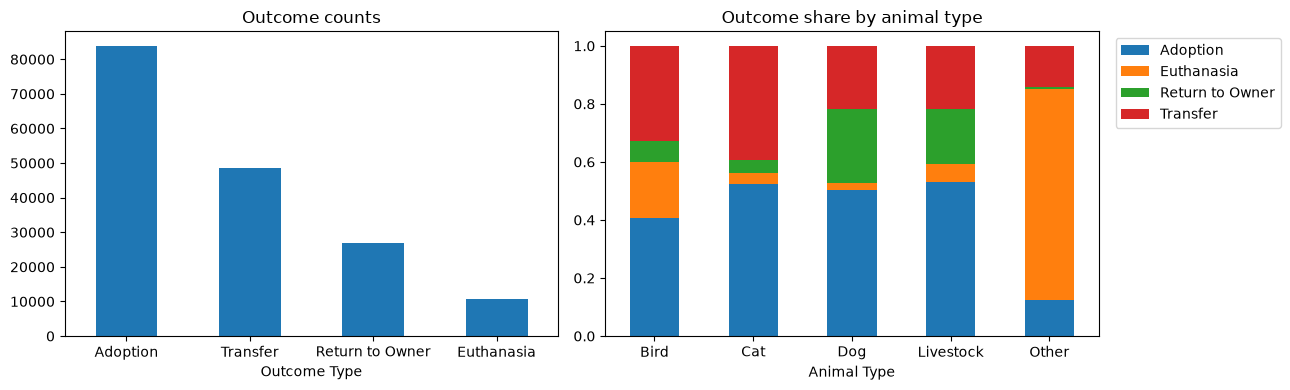

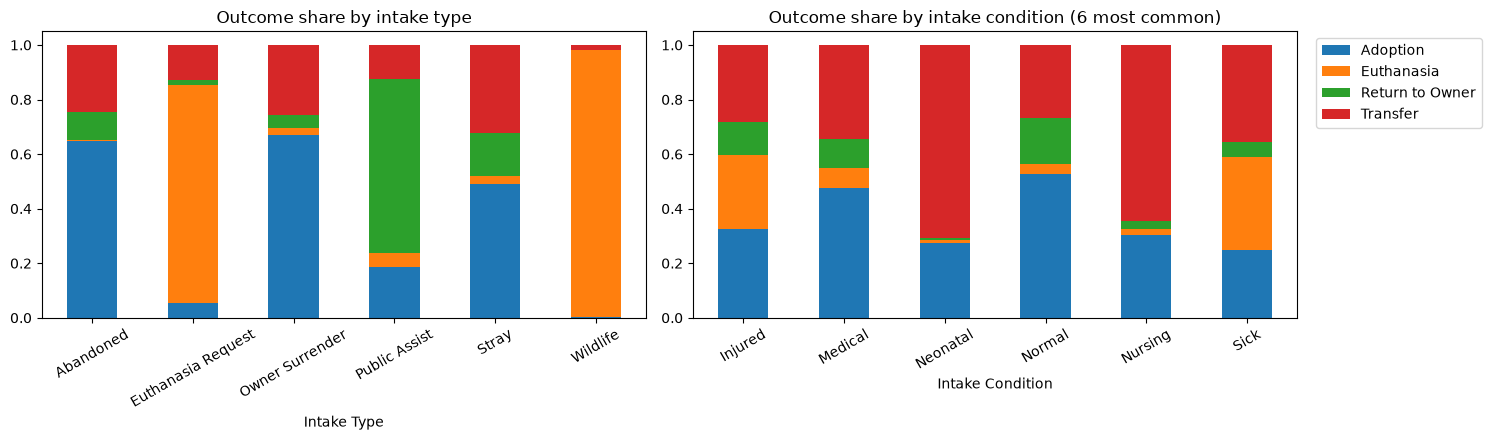

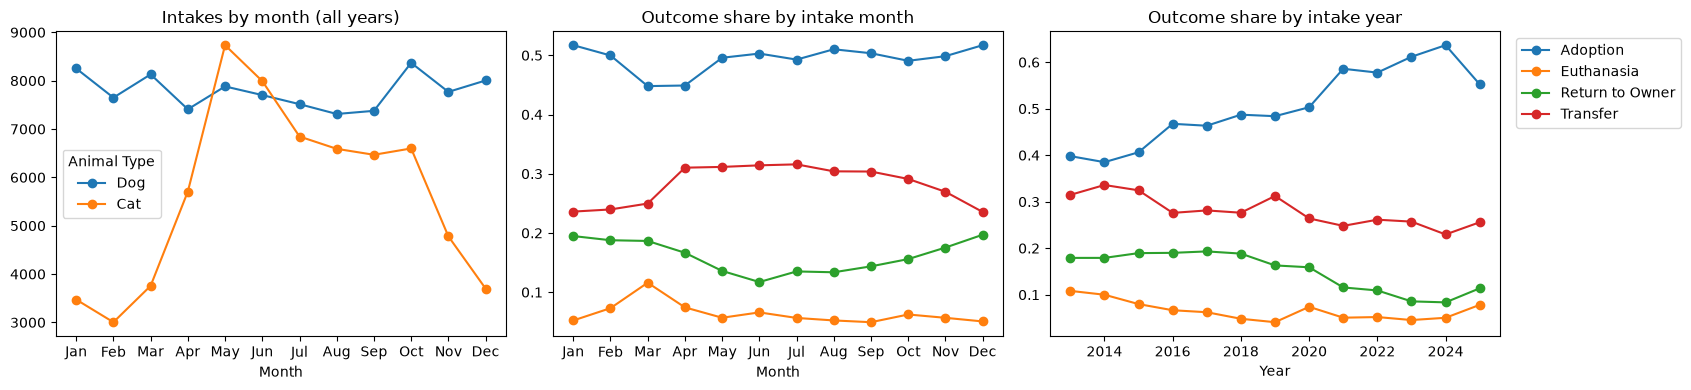

In [126]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df["Outcome Type"].value_counts().plot.bar(ax=ax[0], title="Outcome counts", rot=0)
pd.crosstab(df["Animal Type"], df["Outcome Type"], normalize="index").plot.bar(
    stacked=True, ax=ax[1], title="Outcome share by animal type", rot=0)
ax[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
pd.crosstab(df["Intake Type"], df["Outcome Type"], normalize="index").plot.bar(
    stacked=True, ax=ax[0], title="Outcome share by intake type", rot=30, legend=False)
top_cond = df["Intake Condition"].value_counts().head(6).index
pd.crosstab(df[df["Intake Condition"].isin(top_cond)]["Intake Condition"], df["Outcome Type"],
            normalize="index").plot.bar(stacked=True, ax=ax[1],
            title="Outcome share by intake condition (6 most common)", rot=30)
ax[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()



fig, ax = plt.subplots(1, 3, figsize=(17, 4))
pd.crosstab(df["DateTime"].dt.month, df["Animal Type"])[["Dog", "Cat"]].plot(
    ax=ax[0], marker="o", title="Intakes by month (all years)")
pd.crosstab(df["DateTime"].dt.month, df["Outcome Type"], normalize="index").plot(
    ax=ax[1], marker="o", title="Outcome share by intake month", legend=False)

import calendar

months = list(calendar.month_abbr)[1:]

ax[0].set_xticks(range(1, 13))
ax[0].set_xticklabels(months)

ax[1].set_xticks(range(1, 13))
ax[1].set_xticklabels(months)
pd.crosstab(df["DateTime"].dt.year, df["Outcome Type"], normalize="index").plot(
    ax=ax[2], marker="o", title="Outcome share by intake year")
ax[0].set_xlabel("Month"); ax[1].set_xlabel("Month"); ax[2].set_xlabel("Year")
ax[2].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

## Feature Engineering

In [127]:
# Name
df["Has Name"] = df["Name"].notna().astype(int)
df["Shelter Named"] = df["Name"].str.startswith("*", na=False).astype(int) 

# Sex and spay/neuter status at intake
df["Sex"] = df["Sex upon Intake"].str.extract(r"(Male|Female)")[0].fillna("Unknown")
df["Fixed"] = df["Sex upon Intake"].str.contains("Neutered|Spayed").astype(int)

# Time of intake
df["Month"] = df["DateTime"].dt.month
df["Weekday"] = df["DateTime"].dt.dayofweek
df["Hour"] = df["DateTime"].dt.hour
df["Year"] = df["DateTime"].dt.year

# Top 25 breeds and mix flag, everything else "Other"
df["Is Mix"] = df["Breed"].str.contains("Mix|/").astype(int)
df["Primary Breed"] = df["Breed"].str.replace(" Mix", "", regex=False).str.split("/").str[0]
top_breeds = df["Primary Breed"].value_counts().head(25).index
df["Primary Breed"] = df["Primary Breed"].where(df["Primary Breed"].isin(top_breeds), "Other")

# Group rare intake conditions
cond_counts = df["Intake Condition"].value_counts()
df["Intake Condition"] = df["Intake Condition"].where(df["Intake Condition"].map(cond_counts) >= 500, "Other")

# Build the feature matrix and target
numeric = ["Age", "Visit", "Has Name", "Shelter Named", "Fixed", "Month", "Weekday", "Hour", "Year", "Is Mix"]
categorical = ["Animal Type", "Sex", "Intake Type", "Intake Condition", "Primary Breed"]
X = pd.get_dummies(df[numeric + categorical], columns=categorical, dtype=int)
y = df["Outcome Type"]

print(X.shape)  
display(X.head())

(169954, 58)


,Age,Visit,Has Name,Shelter Named,Fixed,Month,Weekday,Hour,Year,Is Mix,...,Primary Breed_Miniature Poodle,Primary Breed_Miniature Schnauzer,Primary Breed_Other,Primary Breed_Pit Bull,Primary Breed_Pointer,Primary Breed_Raccoon,Primary Breed_Rat Terrier,Primary Breed_Siamese,Primary Breed_Siberian Husky,Primary Breed_Yorkshire Terrier
0,6.0,0,1,0,1,3,4,14,2014,1,...,0,0,1,0,0,0,0,0,0,0
1,7.0,1,1,0,1,12,4,10,2014,1,...,0,0,1,0,0,0,0,0,0,0
2,10.0,2,1,0,1,12,3,14,2017,1,...,0,0,1,0,0,0,0,0,0,0
3,10.0,0,1,0,1,4,2,15,2014,0,...,0,0,0,0,0,0,0,0,0,0
4,16.0,0,1,0,1,11,5,9,2013,0,...,0,0,1,0,0,0,0,0,0,0


## Exploration after feature engineering

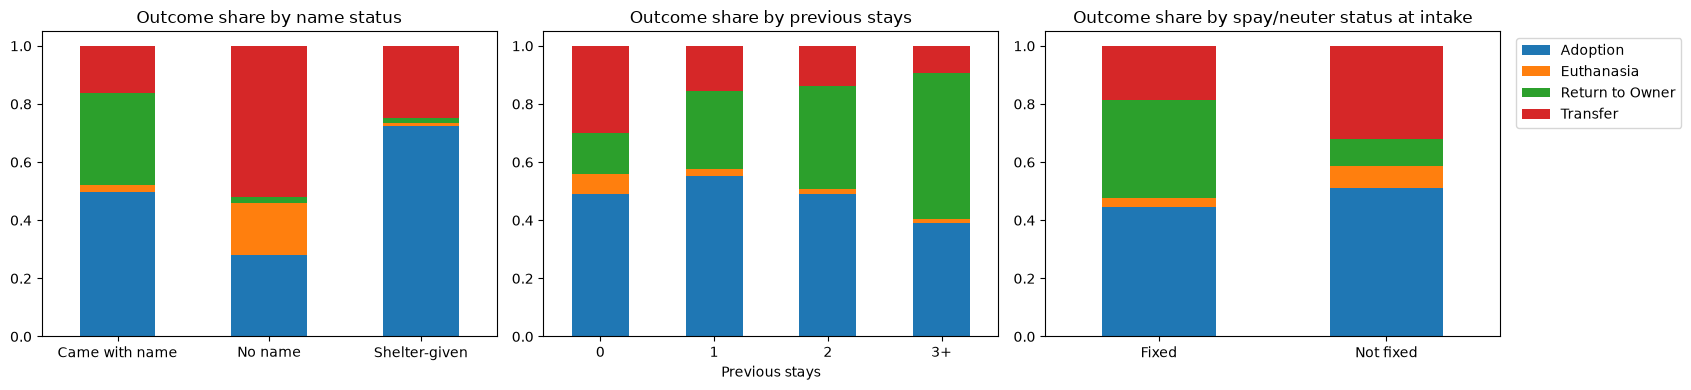

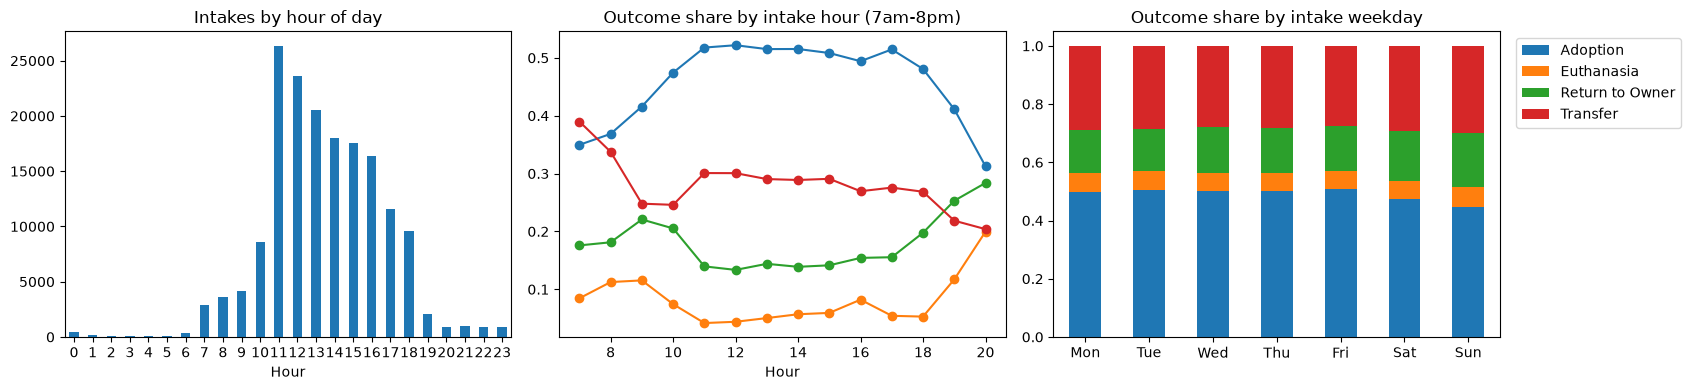

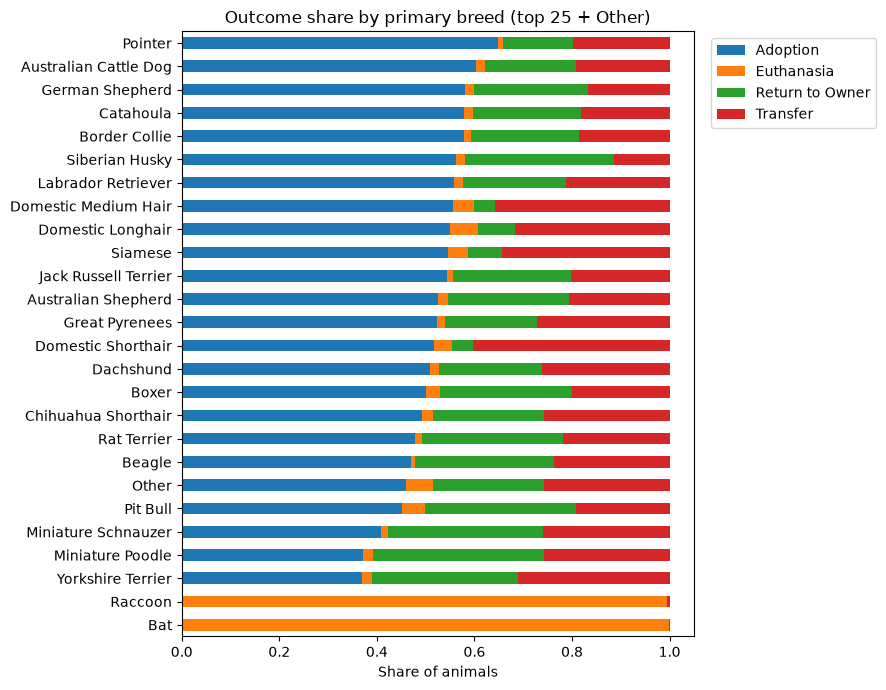

In [128]:
name_status = np.where(df["Shelter Named"] == 1, "Shelter-given",
                       np.where(df["Has Name"] == 1, "Came with name", "No name"))

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
pd.crosstab(name_status, df["Outcome Type"], normalize="index").plot.bar(
    stacked=True, ax=ax[0], rot=0, legend=False, title="Outcome share by name status")
pd.crosstab(df["Visit"].clip(upper=3), df["Outcome Type"], normalize="index").plot.bar(
    stacked=True, ax=ax[1], rot=0, legend=False, title="Outcome share by previous stays")
ax[1].set_xticklabels(["0", "1", "2", "3+"]); ax[1].set_xlabel("Previous stays")
pd.crosstab(df["Fixed"].map({0: "Not fixed", 1: "Fixed"}), df["Outcome Type"], normalize="index").plot.bar(
    stacked=True, ax=ax[2], rot=0, title="Outcome share by spay/neuter status at intake")
ax[0].set_xlabel(""); ax[2].set_xlabel("")
ax[2].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()


fig, ax = plt.subplots(1, 3, figsize=(17, 4))
df["Hour"].value_counts().sort_index().plot.bar(ax=ax[0], rot=0, title="Intakes by hour of day")
pd.crosstab(df["Hour"], df["Outcome Type"], normalize="index").loc[7:20].plot(
    ax=ax[1], marker="o", legend=False, title="Outcome share by intake hour (7am-8pm)")
by_day = pd.crosstab(df["Weekday"], df["Outcome Type"], normalize="index")
by_day.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_day.plot.bar(stacked=True, ax=ax[2], rot=0, title="Outcome share by intake weekday")
ax[2].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

by_breed = pd.crosstab(df["Primary Breed"], df["Outcome Type"], normalize="index").sort_values("Adoption")
by_breed.plot.barh(stacked=True, figsize=(9, 7), title="Outcome share by primary breed (top 25 + Other)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.xlabel("Share of animals"); plt.ylabel("")
plt.tight_layout(); plt.show()

# Modeling: 

In [129]:
from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix

In [130]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)
X_small, _, y_small, _ = train_test_split(X_train, y_train, train_size=20000, stratify=y_train, random_state=0)

print("Train:", X_train.shape, " Test:", X_test.shape, " Comparison sample:", X_small.shape)
print("Majority-class baseline:", round(y_train.value_counts(normalize=True).max(), 3))

Train: (135963, 58)  Test: (33991, 58)  Comparison sample: (20000, 58)
Majority-class baseline: 0.494


,train acc,cv acc,cv macro F1
model,,,
Decision Tree,0.999,0.605,0.595
Logistic Regression,0.672,0.669,0.658
SVM,0.700,0.676,0.658
Neural Network,0.739,0.672,0.665
Random Forest,0.999,0.697,0.685
Gradient Boosting,0.714,0.699,0.687


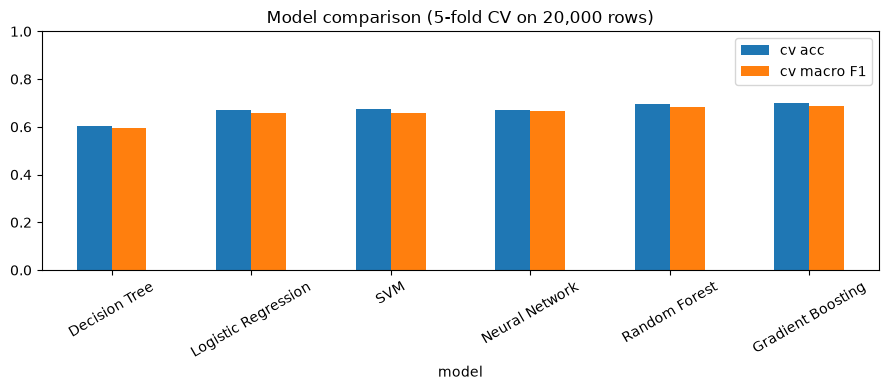

In [131]:
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=0),
    "Logistic Regression": Pipeline([("scale", StandardScaler()), ("model", LogisticRegression(max_iter=1000))]),
    "SVM": Pipeline([("scale", StandardScaler()), ("model", SVC())]),
    "Neural Network": Pipeline([("scale", StandardScaler()),
                                ("model", MLPClassifier(hidden_layer_sizes=(50,), max_iter=500, random_state=0))]),
    "Random Forest": RandomForestClassifier(random_state=0),
    "Gradient Boosting": GradientBoostingClassifier(random_state=0),
}

rows = []
for name, model in models.items():
    scores = cross_validate(model, X_small, y_small, cv=5, scoring=["accuracy", "f1_macro"],
                            return_train_score=True, n_jobs=-1)
    rows.append({"model": name,
                 "train acc": scores["train_accuracy"].mean(),
                 "cv acc": scores["test_accuracy"].mean(),
                 "cv macro F1": scores["test_f1_macro"].mean()})

results = pd.DataFrame(rows).set_index("model").round(3)
display(results)

results[["cv acc", "cv macro F1"]].plot.bar(title="Model comparison (5-fold CV on 20,000 rows)",
                                            rot=30, figsize=(9, 4))
plt.ylim(0, 1); plt.tight_layout(); plt.show()

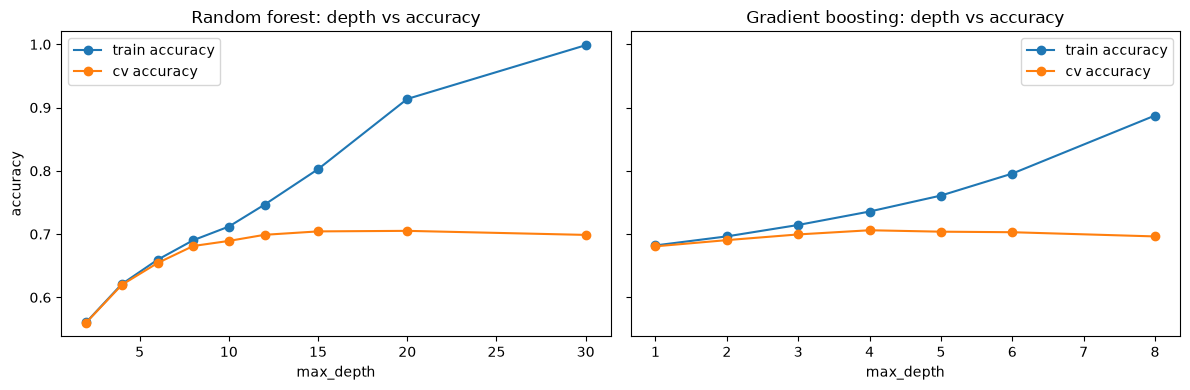

In [132]:
curves = {"Random forest": (RandomForestClassifier, [2, 4, 6, 8, 10, 12, 15, 20, 30]),
          "Gradient boosting": (GradientBoostingClassifier, [1, 2, 3, 4, 5, 6, 8])}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, (Model, depths)) in zip(axes, curves.items()):
    train_scores, cv_scores = [], []
    for depth in depths:
        scores = cross_validate(Model(max_depth=depth, random_state=0),
                                X_small, y_small, cv=5, return_train_score=True, n_jobs=-1)
        train_scores.append(scores["train_score"].mean())
        cv_scores.append(scores["test_score"].mean())
    ax.plot(depths, train_scores, marker="o", label="train accuracy")
    ax.plot(depths, cv_scores, marker="o", label="cv accuracy")
    ax.set_xlabel("max_depth"); ax.set_title(name + ": depth vs accuracy"); ax.legend()
axes[0].set_ylabel("accuracy")
plt.tight_layout(); plt.show()

In [ ]:
rf_grid = GridSearchCV(RandomForestClassifier(random_state=0),
    {"n_estimators": [100, 300], "max_depth": [10, 20, 30, None], "min_samples_leaf": [1, 5]},
    cv=5, scoring="f1_macro", n_jobs=-1).fit(X_small, y_small)

gb_grid = GridSearchCV(GradientBoostingClassifier(random_state=0),
    {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "max_depth": [3, 5]},
    cv=3, scoring="f1_macro", n_jobs=-1).fit(X_small, y_small)

for name, grid in [("Random Forest", rf_grid), ("Gradient Boosting", gb_grid)]:
    print(name, grid.best_params_, "cv macro F1:", round(grid.best_score_, 3))


Random Forest {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 300} cv macro F1: 0.69
Gradient Boosting {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200} cv macro F1: 0.69


### Final Model

,train acc,test acc
model,,
Random Forest,0.812,0.730
Gradient Boosting,0.713,0.714


Train acc: 0.812  Test acc: 0.73
                 precision    recall  f1-score   support

       Adoption       0.71      0.89      0.79     16776
     Euthanasia       0.91      0.68      0.78      2158
Return to Owner       0.68      0.69      0.69      5368
       Transfer       0.80      0.49      0.61      9689

       accuracy                           0.73     33991
      macro avg       0.78      0.69      0.72     33991
   weighted avg       0.74      0.73      0.72     33991



,Adoption,Euthanasia,Return to Owner,Transfer
Adoption,14860,25,1117,774
Euthanasia,273,1475,110,300
Return to Owner,1531,10,3714,113
Transfer,4327,103,494,4765


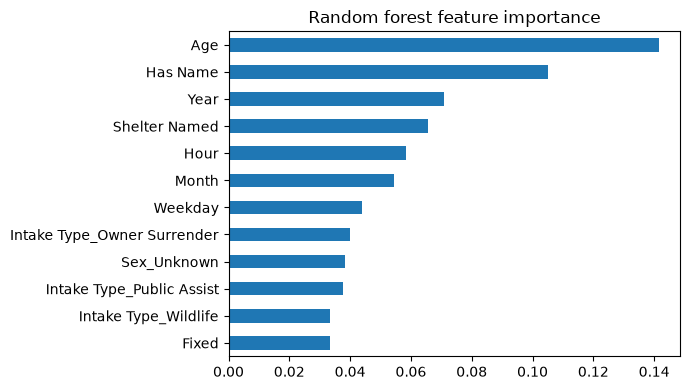

Dog 18607 test animals, accuracy 0.678
Cat 13564 test animals, accuracy 0.777
Other 1656 test animals, accuracy 0.943
Bird 160 test animals, accuracy 0.631


In [134]:
tuned = {"Random Forest": RandomForestClassifier(random_state=0, n_jobs=-1, **rf_grid.best_params_),
         "Gradient Boosting": GradientBoostingClassifier(random_state=0, **gb_grid.best_params_)}
rows = []
for name, model in tuned.items():
    model.fit(X_train, y_train)
    rows.append({"model": name, "train acc": model.score(X_train, y_train), "test acc": model.score(X_test, y_test)})
display(pd.DataFrame(rows).set_index("model").round(3))

final = tuned["Random Forest"]
pred = final.predict(X_test)

print("Train acc:", round(final.score(X_train, y_train), 3), " Test acc:", round(final.score(X_test, y_test), 3))
print(classification_report(y_test, pred))
display(pd.DataFrame(confusion_matrix(y_test, pred, labels=final.classes_),
                     index=final.classes_, columns=final.classes_))

pd.Series(final.feature_importances_, index=X.columns).sort_values().tail(12).plot.barh(
    title="Random forest feature importance", figsize=(7, 4))
plt.tight_layout(); plt.show()

animal_type = df.loc[X_test.index, "Animal Type"]
for a in ["Dog", "Cat", "Other", "Bird"]:
    mask = (animal_type == a).values
    print(a, mask.sum(), "test animals, accuracy", round((pred[mask] == y_test[mask]).mean(), 3))
